# Setting up

In [1]:
# Data handlers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Models
from scipy.optimize import minimize_scalar, curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
import xgboost
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import tensorflow as tf


# Preprocessors
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Evaluators
from sklearn.metrics import r2_score, mean_absolute_error as mae, mean_squared_error as mse


In [2]:
df = pd.read_csv('cleaned data.csv')
df.head()

,variable 1,variable 2,Output
0,30,30,2315.7
1,30,35,1932.6
2,30,40,1592.2
3,30,45,1316.6
4,30,50,1099.5


In [3]:
X = df.drop(columns = 'Output')
Y = df['Output']

In [4]:
X.to_numpy()

array([[ 30,  30],
       [ 30,  35],
       [ 30,  40],
       [ 30,  45],
       [ 30,  50],
       [ 30,  55],
       [ 30,  60],
       [ 30,  65],
       [ 30,  70],
       [ 30,  75],
       [ 30,  80],
       [ 30,  85],
       [ 30,  90],
       [ 30,  95],
       [ 30, 100],
       [ 30, 105],
       [ 30, 110],
       [ 30, 115],
       [ 30, 120],
       [ 30, 125],
       [ 30, 130],
       [ 30, 135],
       [ 30, 140],
       [ 30, 145],
       [ 30, 150],
       [ 35,  35],
       [ 35,  40],
       [ 35,  45],
       [ 35,  50],
       [ 35,  55],
       [ 35,  60],
       [ 35,  65],
       [ 35,  70],
       [ 35,  75],
       [ 35,  80],
       [ 35,  85],
       [ 35,  90],
       [ 35,  95],
       [ 35, 100],
       [ 35, 105],
       [ 35, 110],
       [ 35, 115],
       [ 35, 120],
       [ 35, 125],
       [ 35, 130],
       [ 35, 135],
       [ 35, 140],
       [ 35, 145],
       [ 35, 150],
       [ 40,  40],
       [ 40,  45],
       [ 40,  50],
       [ 40,

# Plotting function

In [5]:
var1 = df['variable 1'].unique()
var2 = df['variable 2'].unique()


def plot2d_var1const(model):

    fig,ax = plt.subplots(5,5, figsize = (20,20))

    for i in range(5):
        for j in range(5):
            temp = df[df['variable 1'] == var1[5*i+j]]
            ax[i,j].plot(temp['variable 2'], temp['Output'], marker = 'o')
            ax[i,j].plot(temp['variable 2'], temp[model], marker = 'o')
            ax[i,j].set_title('variable 1 = '+str(var1[5*i+j]))

    plt.show()


def plot2d_var2const(model):

    fig,ax = plt.subplots(5,5, figsize = (20,20))

    for i in range(5):
        for j in range(5):
            temp = df[df['variable 2'] == var1[5*i+j]]
            ax[i,j].plot(temp['variable 1'], temp['Output'], marker = 'o')
            ax[i,j].plot(temp['variable 1'], temp[model], marker = 'o')
            ax[i,j].set_title('variable 2 = '+str(var2[5*i+j]))

    plt.show()

def plot3d(model):
    fig = plt.figure(figsize = (10,10))
    ax = fig.add_subplot(projection = '3d')
    ax.scatter(df['variable 1'], df['variable 2'], df['Output'], marker = 'o', color = 'blue', alpha = 0.25)
    ax.scatter(df['variable 1'], df['variable 2'], df[model], marker = 'o', color = 'orange')
    ax.set_xlabel('Var 1')
    ax.set_ylabel('Var 2')
    ax.set_zlabel('Output')
    plt.show()

# Custom curve fit

In [6]:
def model_eq(X,k1,k2,k3,k4,k5,k6,k7):
    y,x = X
    return k2*y*np.exp(-k1*x) + k3*np.exp(-k1*x) - k4*x*y + k5*x + k6*y + k7

p0 = [0.1, 1.0, 1.0, 0., 0., 0., 0.]
lower_bounds = [0.001, -np.inf, -np.inf, -np.inf, -np.inf, -np.inf, -np.inf]
upper_bounds = [np.inf, np.inf, np.inf, np.inf, np.inf, np.inf, np.inf]
bounds = (lower_bounds, upper_bounds)

popt,pcov = curve_fit(model_eq,X.to_numpy().T,Y,p0 = p0, bounds = bounds)

popt

array([ 4.63869715e-02, -1.18760527e+02,  1.10415419e+04, -3.69927315e-03,
       -2.52547651e+00, -8.50445143e-01,  5.13734496e+02])

In [7]:
df['custom'] = model_eq(X.to_numpy().T, *popt)

print(mse(Y, df['custom']))

113.79039603805539


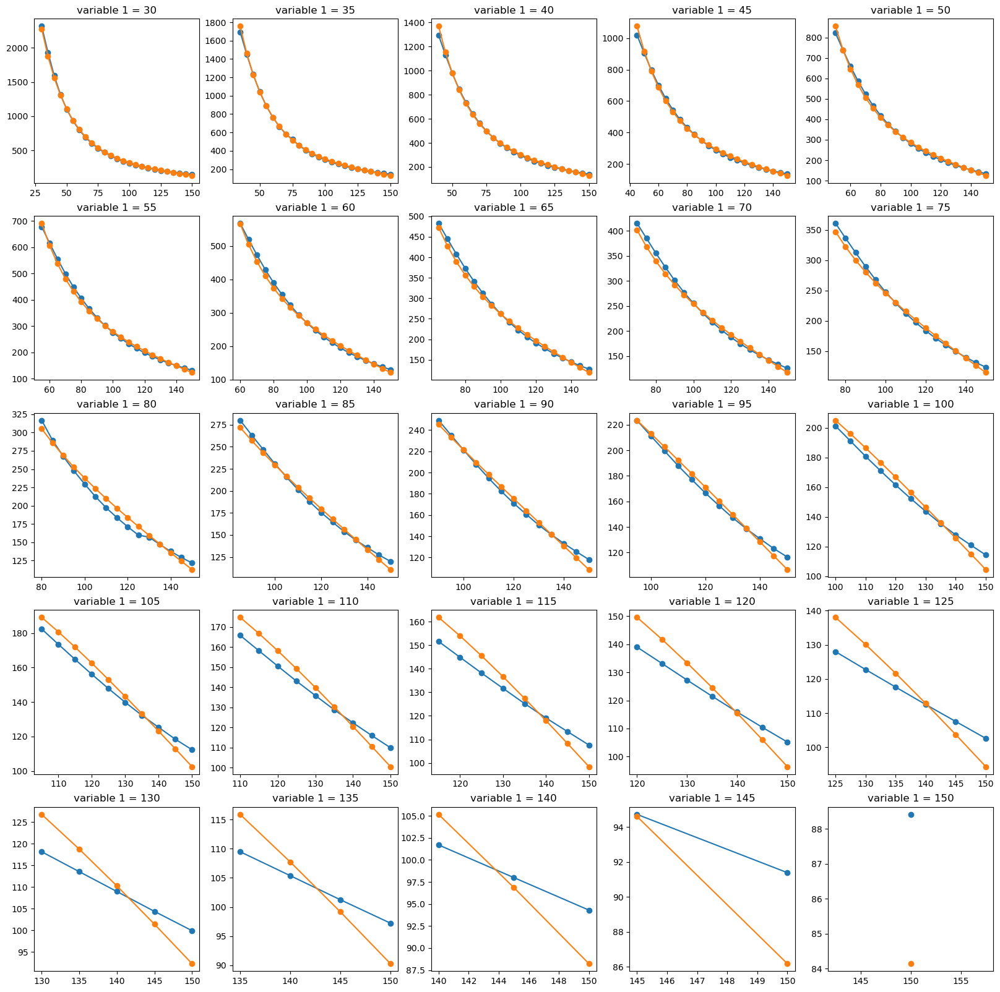

In [8]:
plot2d_var1const('custom')

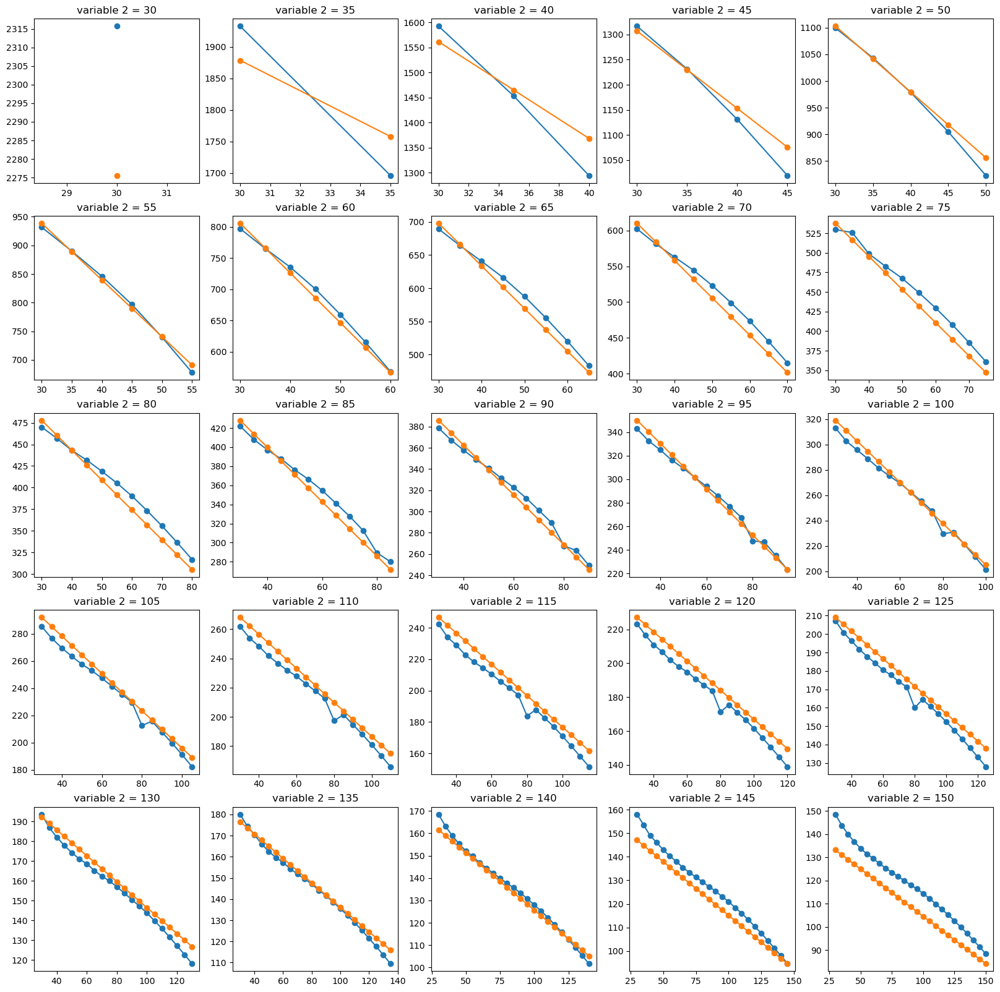

In [9]:
plot2d_var2const('custom')

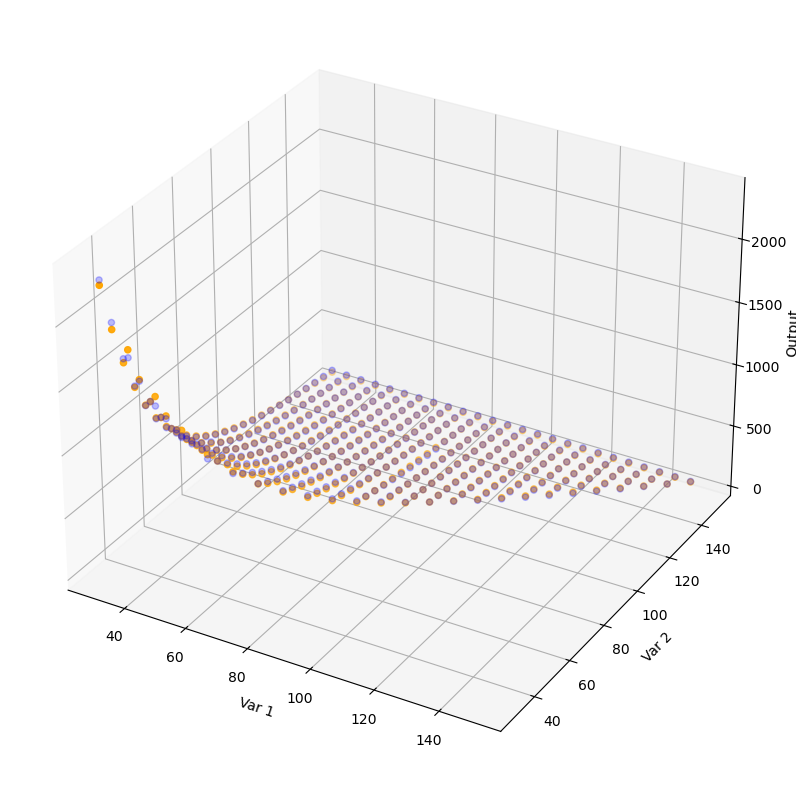

In [10]:
plot3d('custom')

# Linear Regression

In [11]:
LinReg = LinearRegression()
LinReg.fit(X,Y)
df['Linreg'] = LinReg.predict(X)
print(mse(Y, df['Linreg']))

26034.305095744785


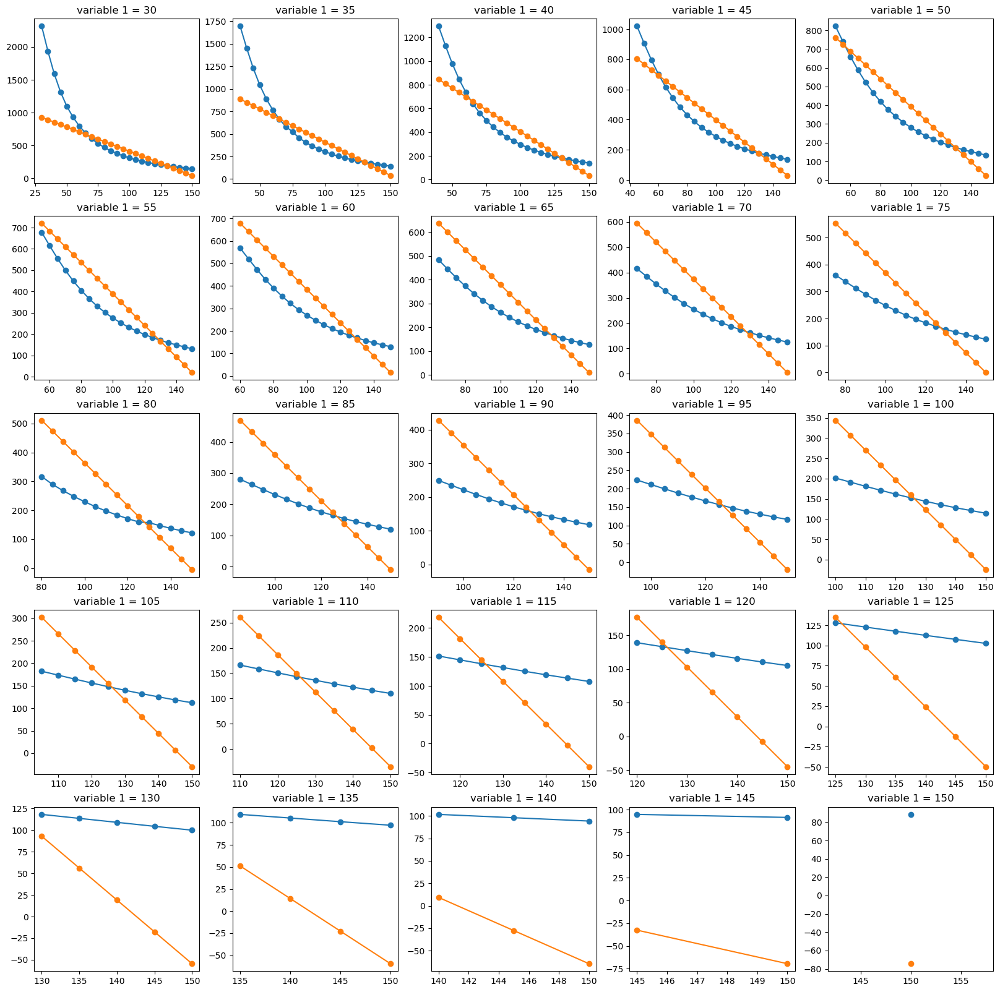

In [12]:
plot2d_var1const('Linreg')

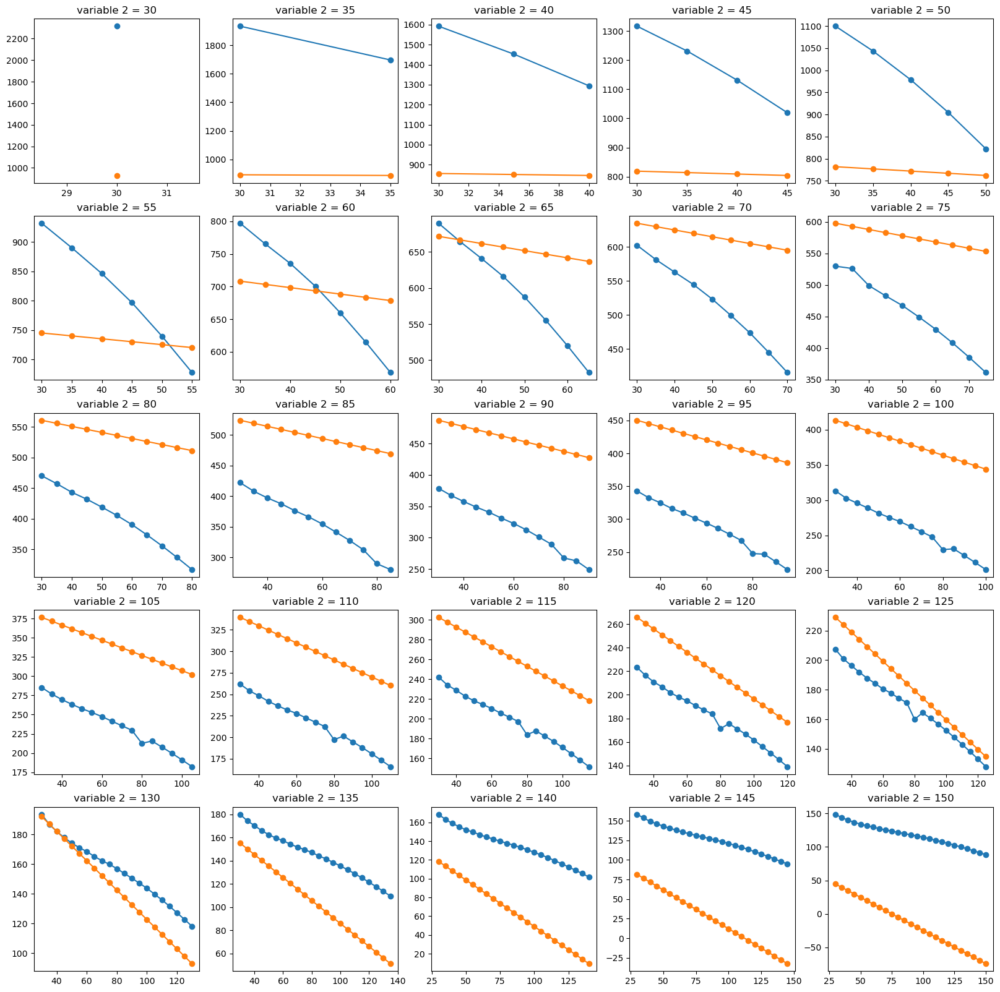

In [13]:
plot2d_var2const('Linreg')

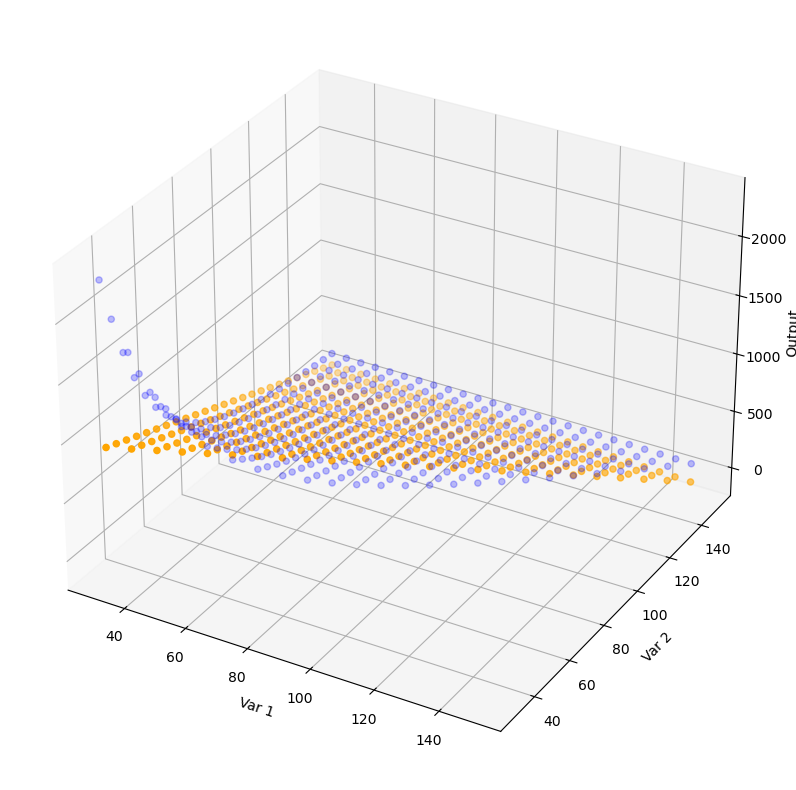

In [14]:
plot3d('Linreg')

# Decision Tree Regressor

In [15]:
DTReg = DecisionTreeRegressor(random_state = 0, max_depth = 4, min_samples_split = 2)
DTReg.fit(X,Y)
df['DTReg'] = DTReg.predict(X)
print(mse(Y, df['DTReg']))

1649.0956632380858


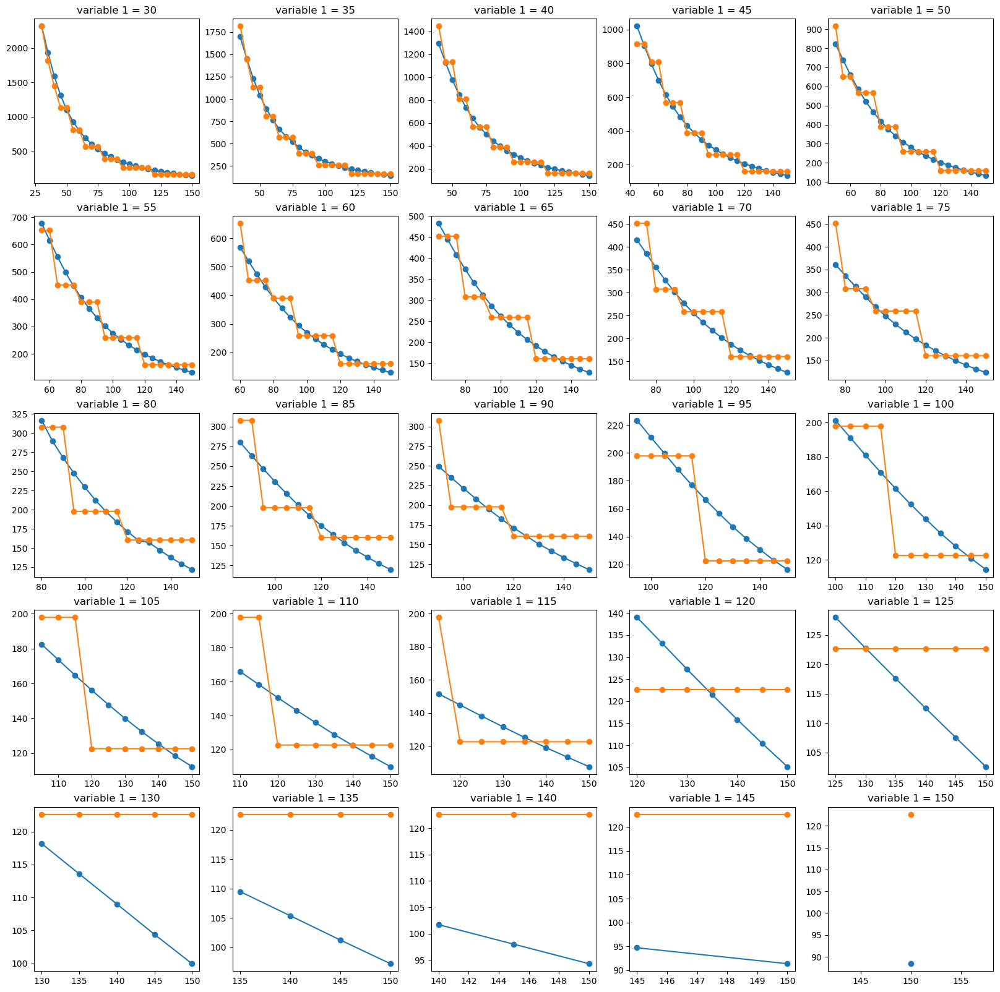

In [16]:
plot2d_var1const('DTReg')

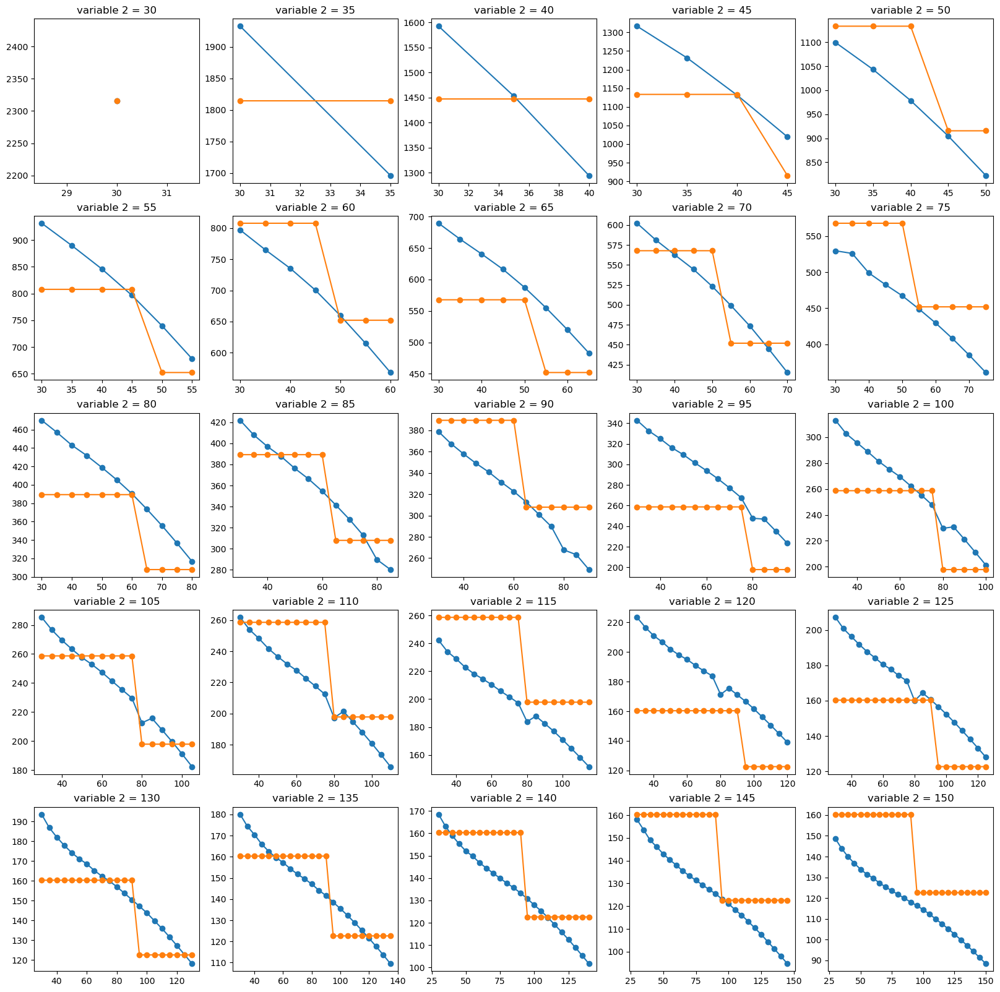

In [17]:
plot2d_var2const('DTReg')

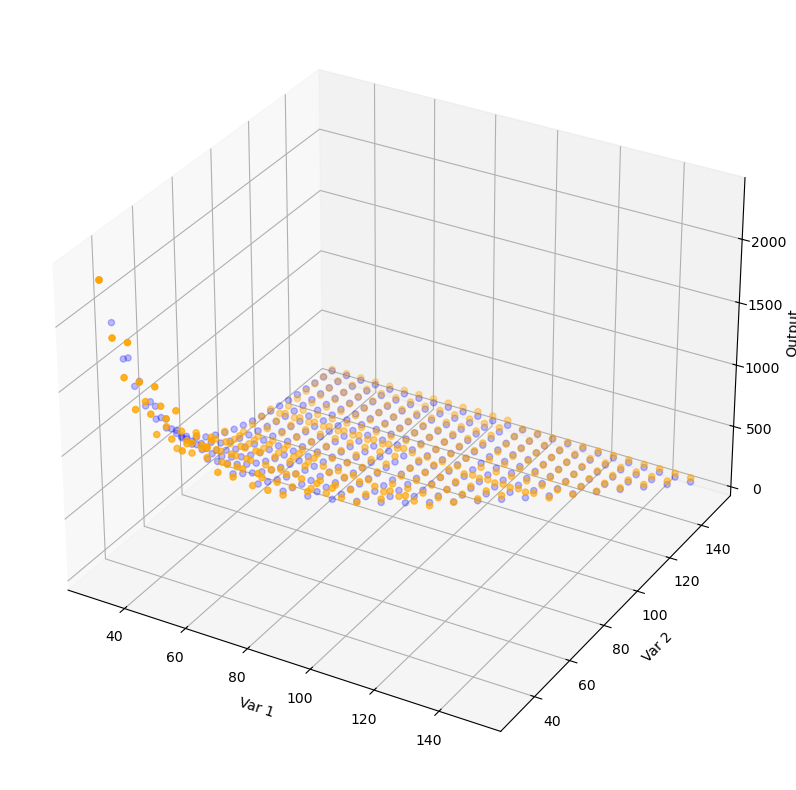

In [18]:
plot3d('DTReg')

# Random Forest Regressor

In [19]:
RFReg = RandomForestRegressor(
    n_estimators = 10,
    random_state = 0,
    oob_score = True,
    max_depth = 8
)


RFReg.fit(X,Y)
df['RFReg'] = RFReg.predict(X)
print(mse(Y, df['RFReg']), '\n',
      RFReg.oob_score_)

155.83846325125603 
 0.9704475533876075


c:\Users\rajee\miniconda3\envs\tfenv\lib\site-packages\sklearn\ensemble\_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


In [20]:
# import pickle

# with open('./Models/RFReg.pkl', 'wb') as file:
#     pickle.dump(RFReg, file)
#     print('pickle dump success')

In [21]:
[estimator.get_depth() for estimator in RFReg.estimators_]

[8, 8, 8, 8, 8, 8, 8, 8, 8, 8]

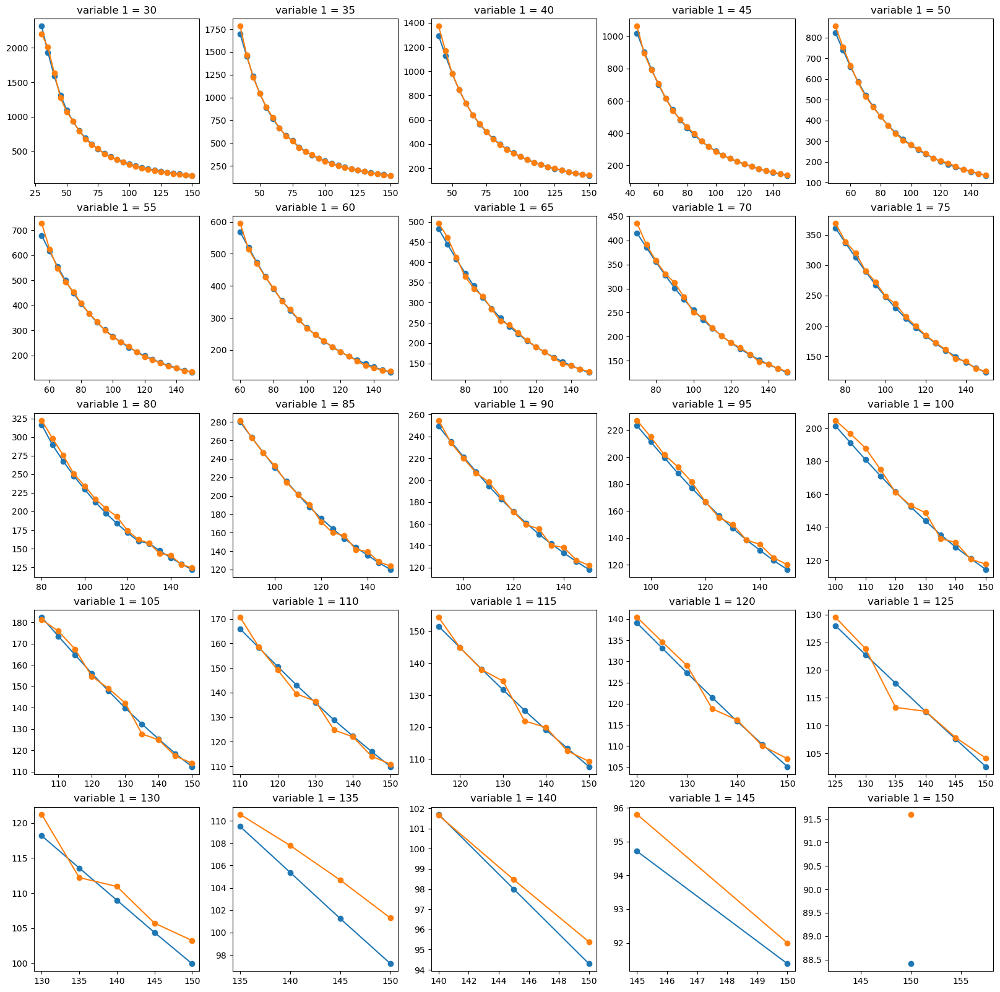

In [22]:
plot2d_var1const('RFReg')

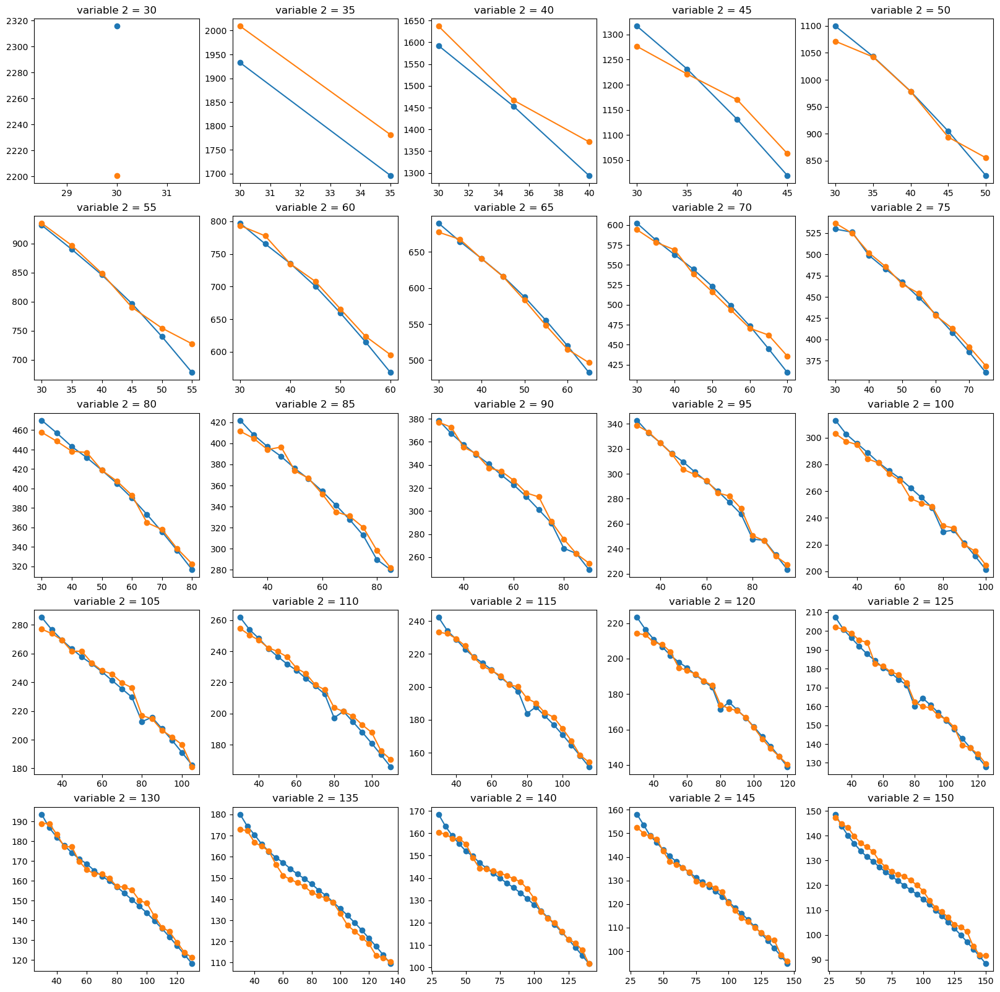

In [23]:
plot2d_var2const('RFReg')

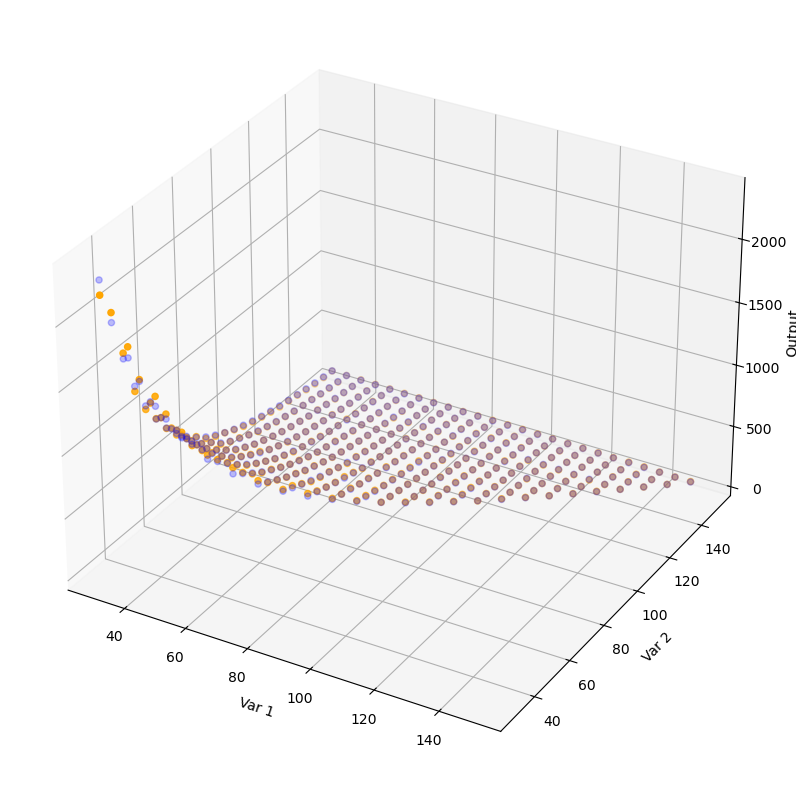

In [24]:
plot3d('RFReg')

# Gradient Boosting Regressor

In [25]:
GBR = GradientBoostingRegressor(loss = 'squared_error',
                                learning_rate = 0.1,
                                n_estimators = 40,
                                # max_depth = 3,
                                random_state = 0)

GBR.fit(X,Y)
df['GBR'] = GBR.predict(X)
print(mse(Y, df['GBR']))

92.55233764248817


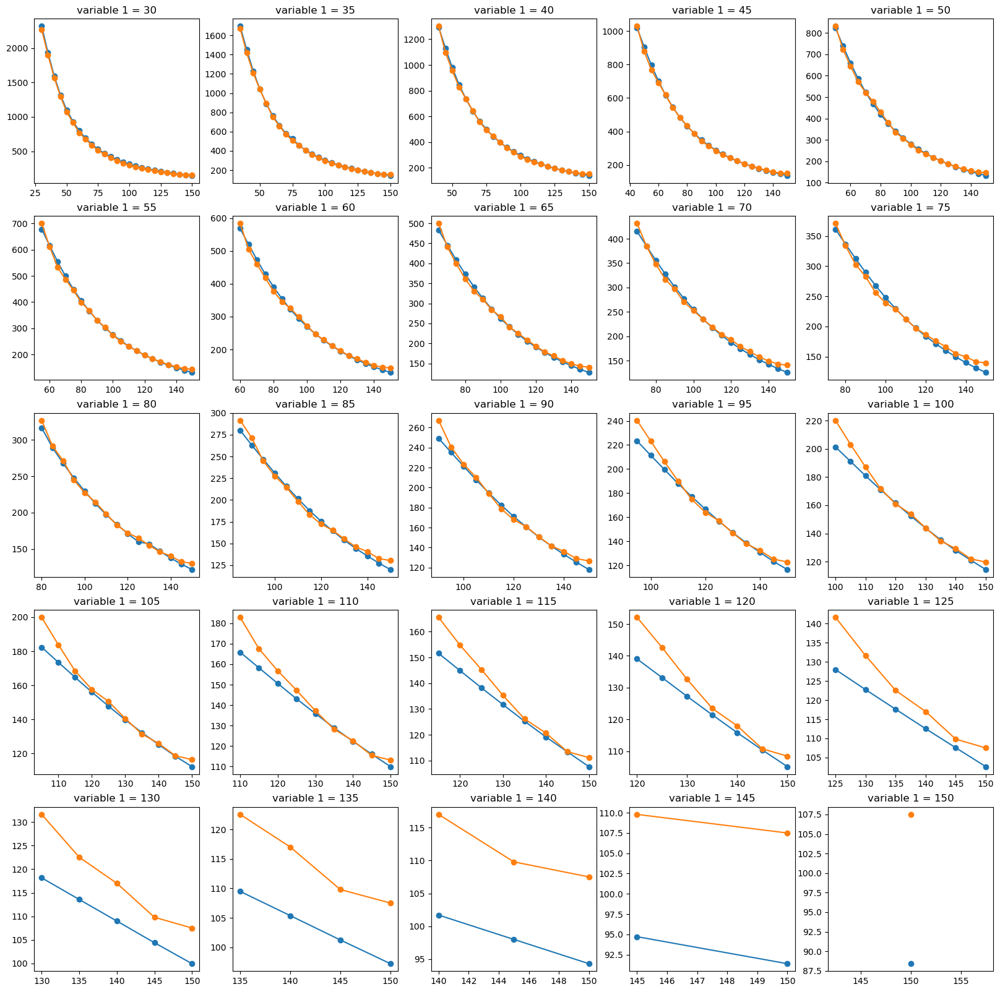

In [26]:
plot2d_var1const('GBR')

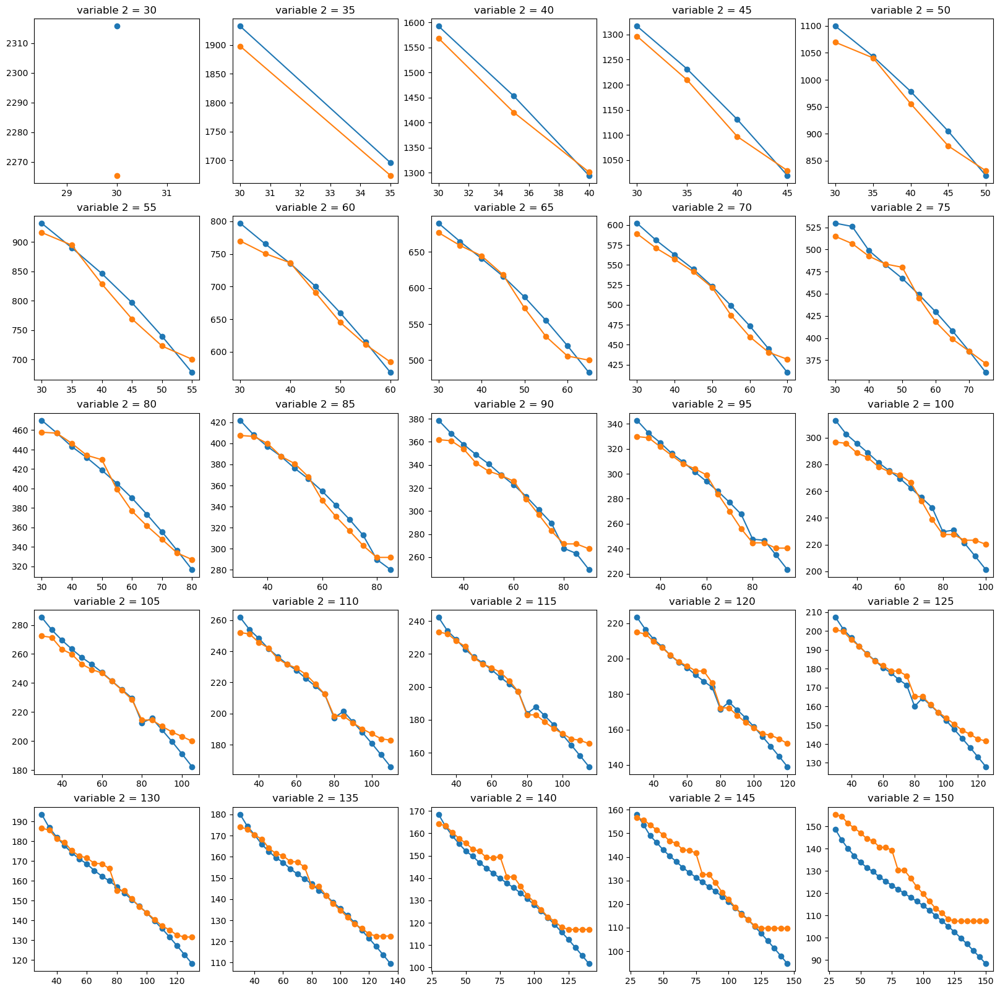

In [27]:
plot2d_var2const('GBR')

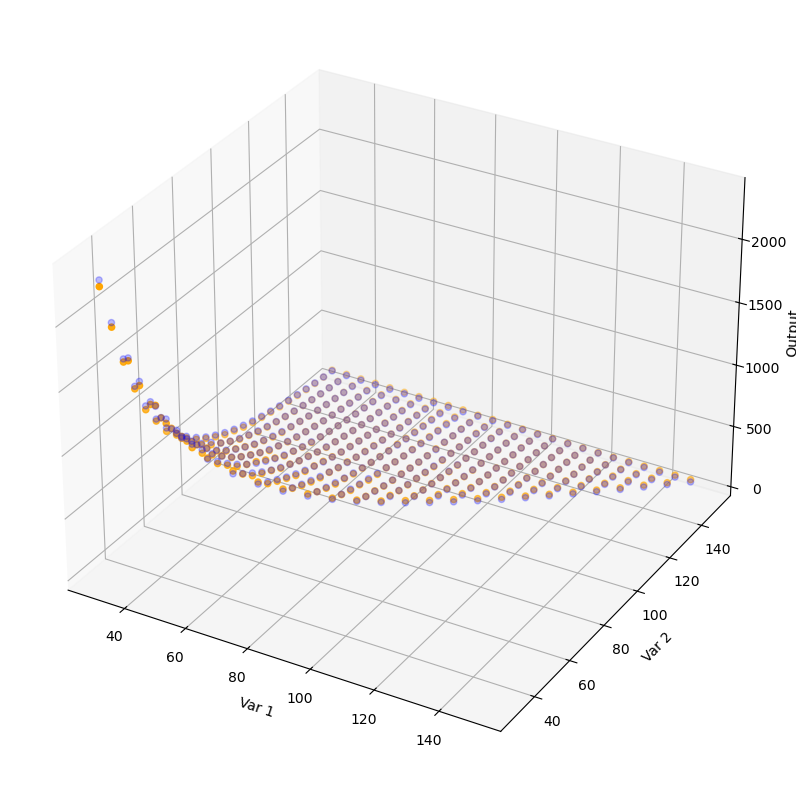

In [28]:
plot3d('GBR')

# AdaBoost Regressor

In [29]:
dtr = DecisionTreeRegressor(max_depth = 3)

ABR = AdaBoostRegressor(estimator = dtr,
                        n_estimators = 10,
                        learning_rate = 0.1,
                        loss = 'linear',
                        random_state = 0)

ABR.fit(X,Y)
df['ABR'] = ABR.predict(X)
print(mse(Y, df['ABR']))

1970.873634056997


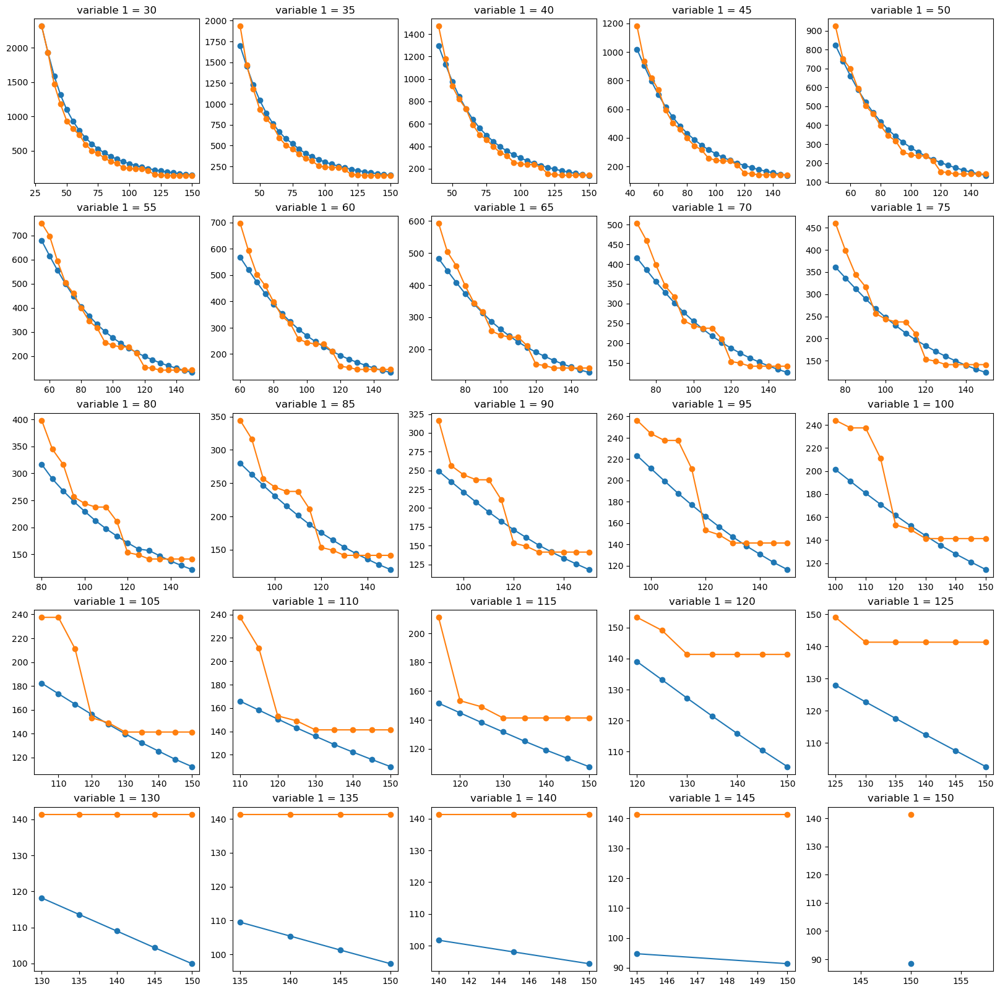

In [30]:
plot2d_var1const('ABR')

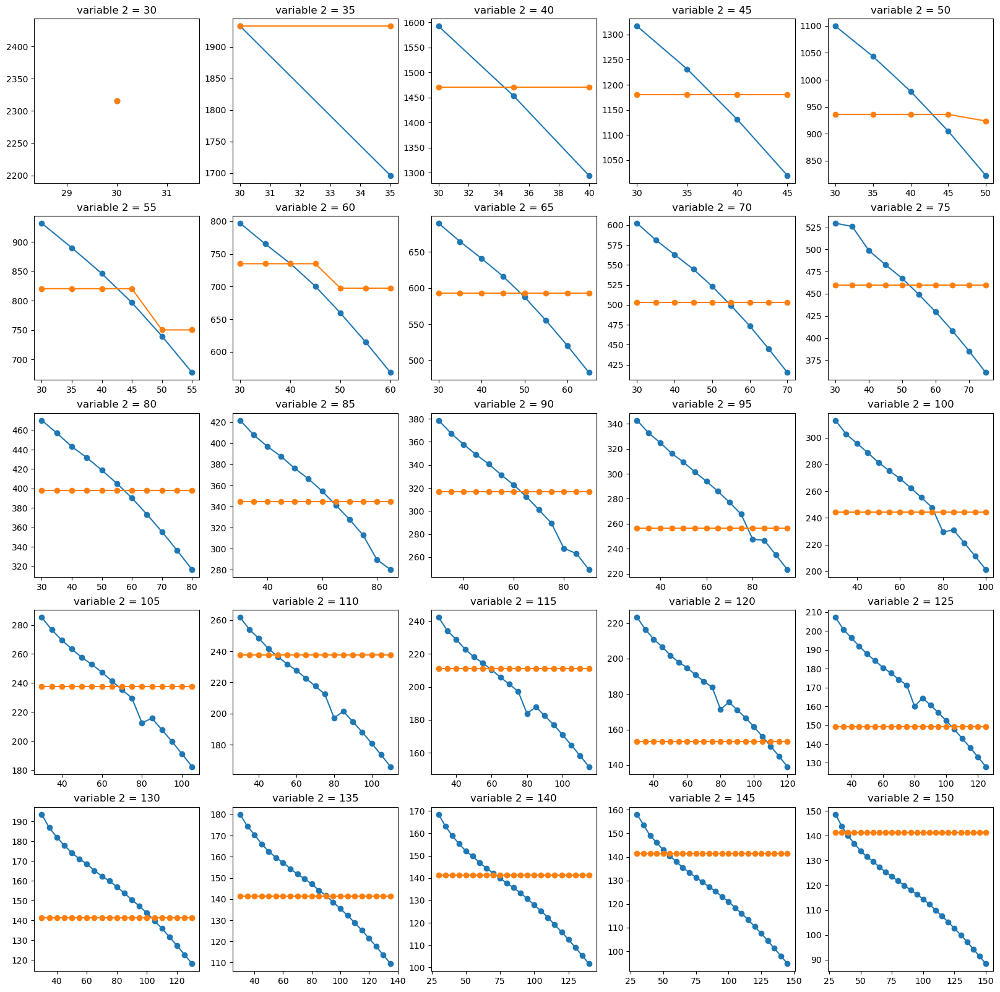

In [31]:
plot2d_var2const('ABR')

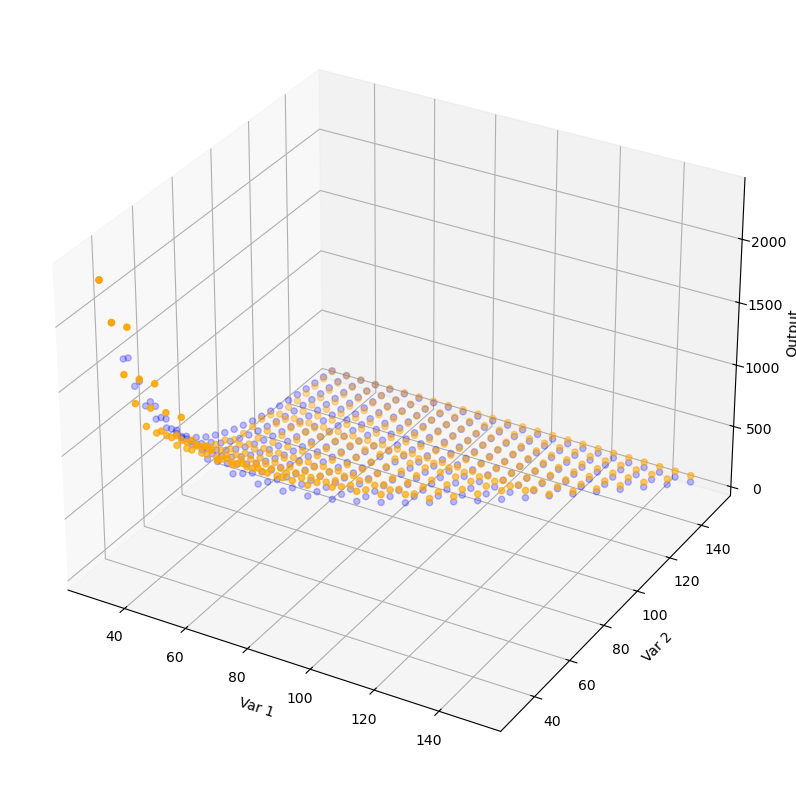

In [32]:
plot3d('ABR')

# XGBoost

In [33]:
XGB = xgboost.XGBRegressor(objective = 'reg:squarederror',
                        n_estimators = 10,
                        random_state = 0)

XGB.fit(X,Y)
df['XGB'] = XGB.predict(X)

print(mse(Y, df['XGB']))

677.190049978358


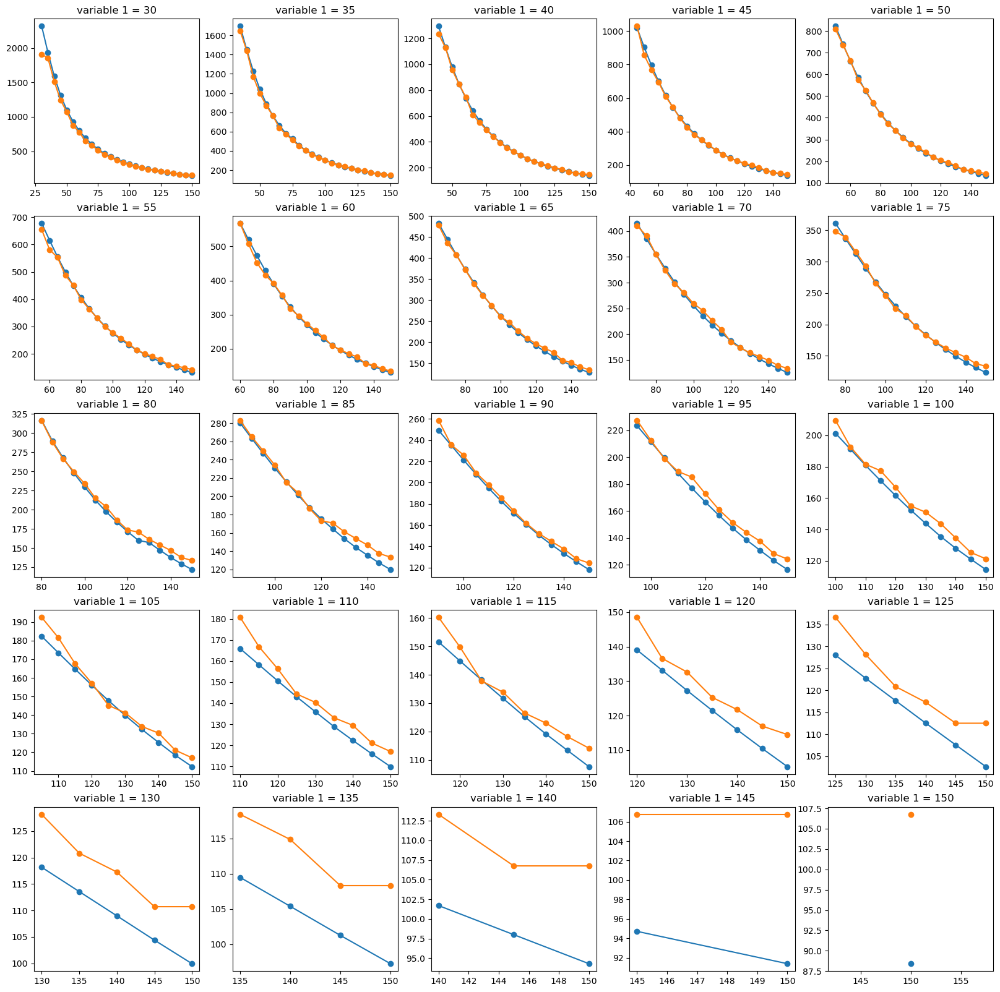

In [34]:
plot2d_var1const('XGB')

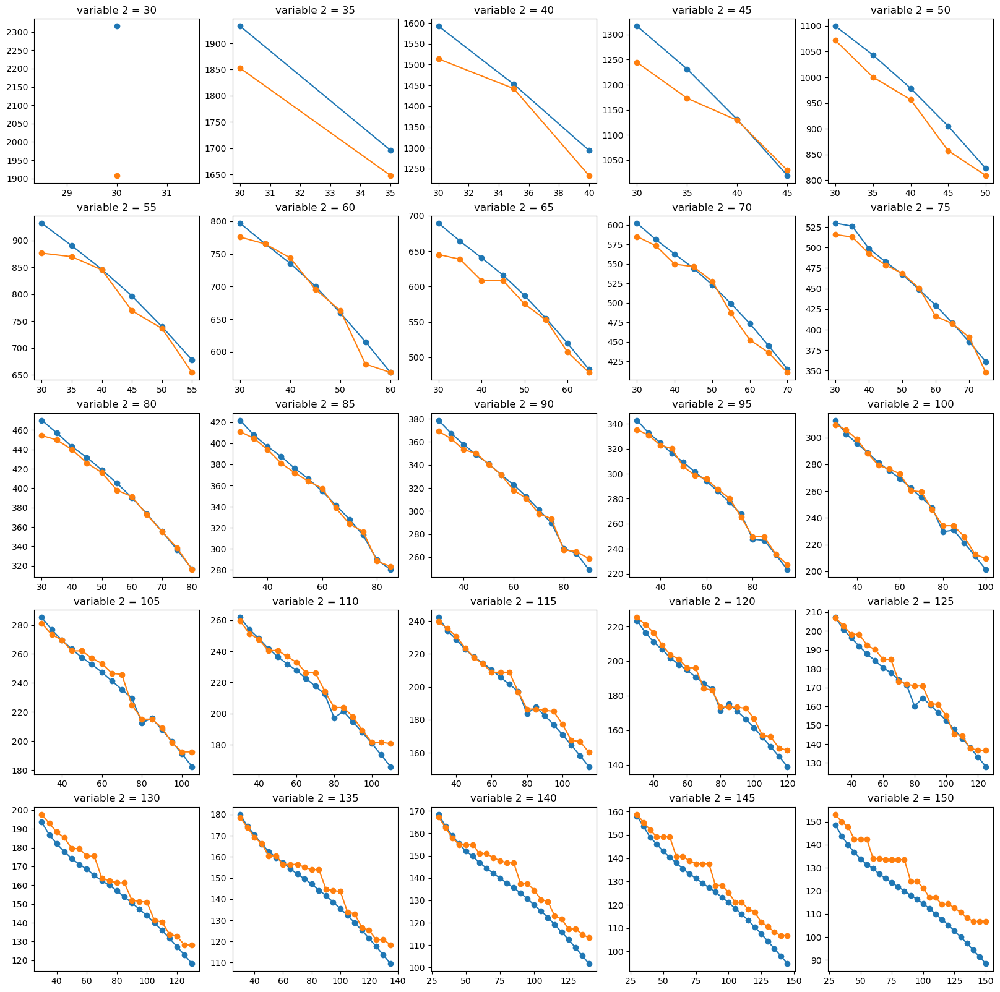

In [35]:
plot2d_var2const('XGB')

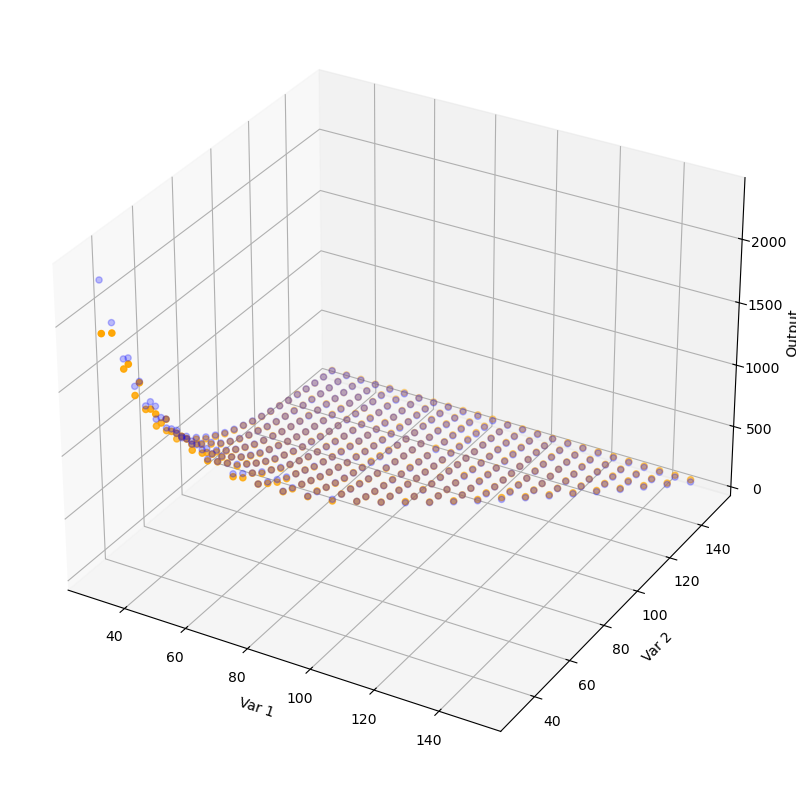

In [36]:
plot3d('XGB')

# LightGBM

In [37]:
LGBM = LGBMRegressor(metric = 'rmse')
LGBM.fit(X,Y)
df['LGBM'] = LGBM.predict(X)
print(mse(Y,df['LGBM']))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000055 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 50
[LightGBM] [Info] Number of data points in the train set: 325, number of used features: 2
[LightGBM] [Info] Start training from score 299.897862
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

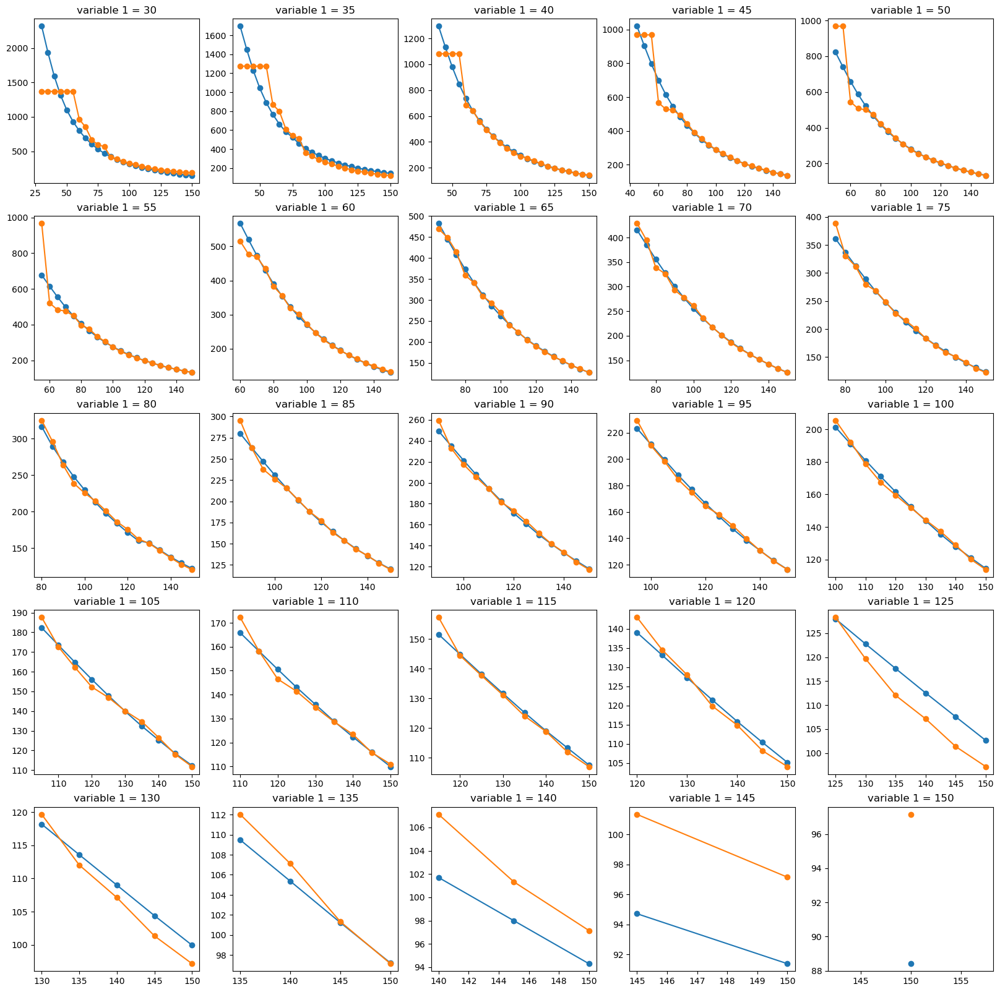

In [38]:
plot2d_var1const('LGBM')

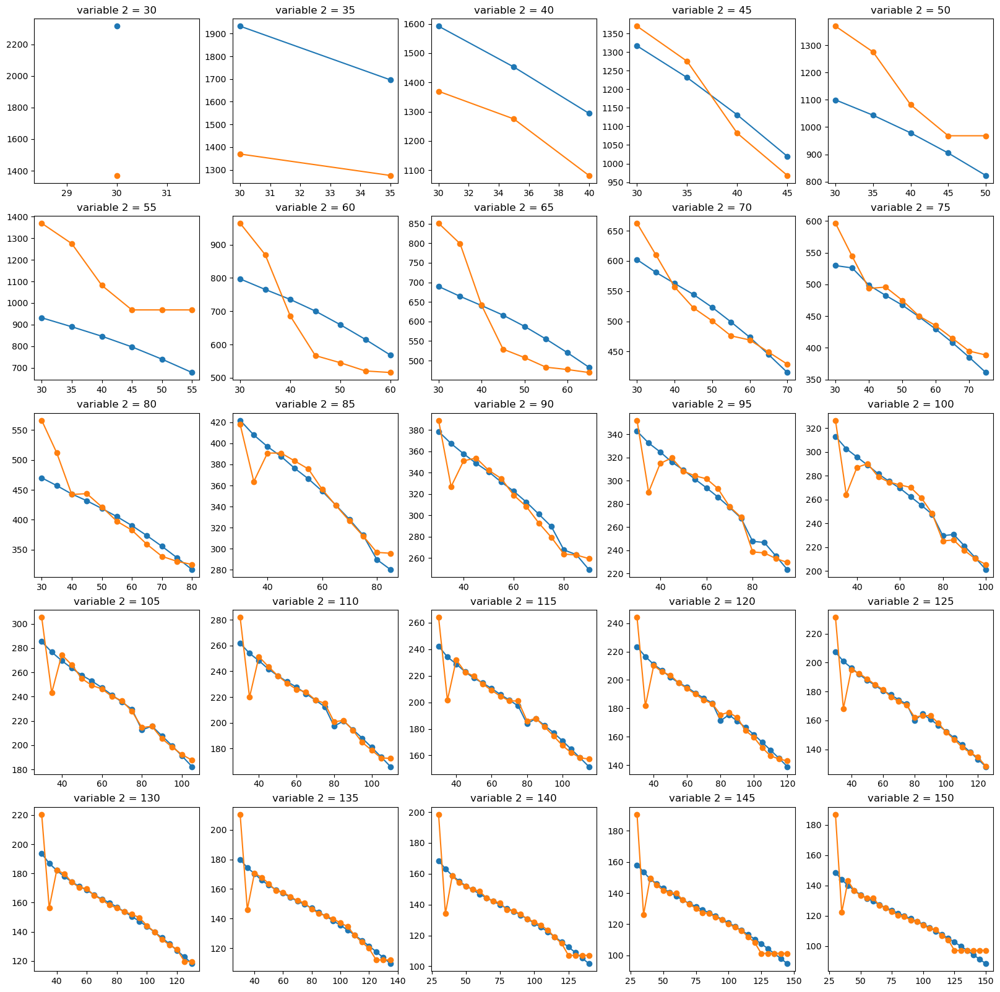

In [39]:
plot2d_var2const('LGBM')

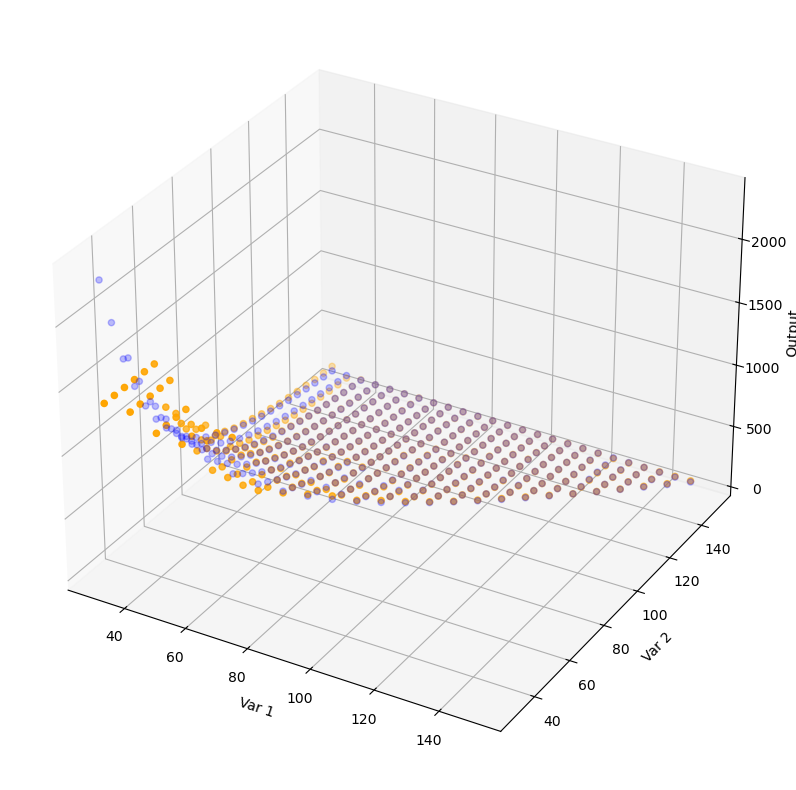

In [40]:
plot3d('LGBM')

# NN

In [41]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

scaler_Y = StandardScaler()
Y = scaler_Y.fit_transform(Y.values.reshape(-1,1))

In [42]:
NN = tf.keras.models.Sequential([
    tf.keras.layers.Dense(10, activation = 'relu', input_shape = (2,)),
    tf.keras.layers.Dense(10, activation = 'relu'),
    tf.keras.layers.Dense(1)
])

NN.compile(
    optimizer = 'adam',
    loss = 'mse',
    # metrics = ['mae']
)

history = NN.fit(X,Y, epochs = 5)

df['NN'] = scaler_Y.inverse_transform(NN.predict(X).reshape(-1,1))
print(mse(Y, df['NN']))

c:\Users\rajee\miniconda3\envs\tfenv\lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.0367
Epoch 2/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9326 
Epoch 3/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8423 
Epoch 4/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7625 
Epoch 5/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7016 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
85066.41132446608


In [43]:
NN.evaluate(X,Y)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6665 


0.6664860248565674

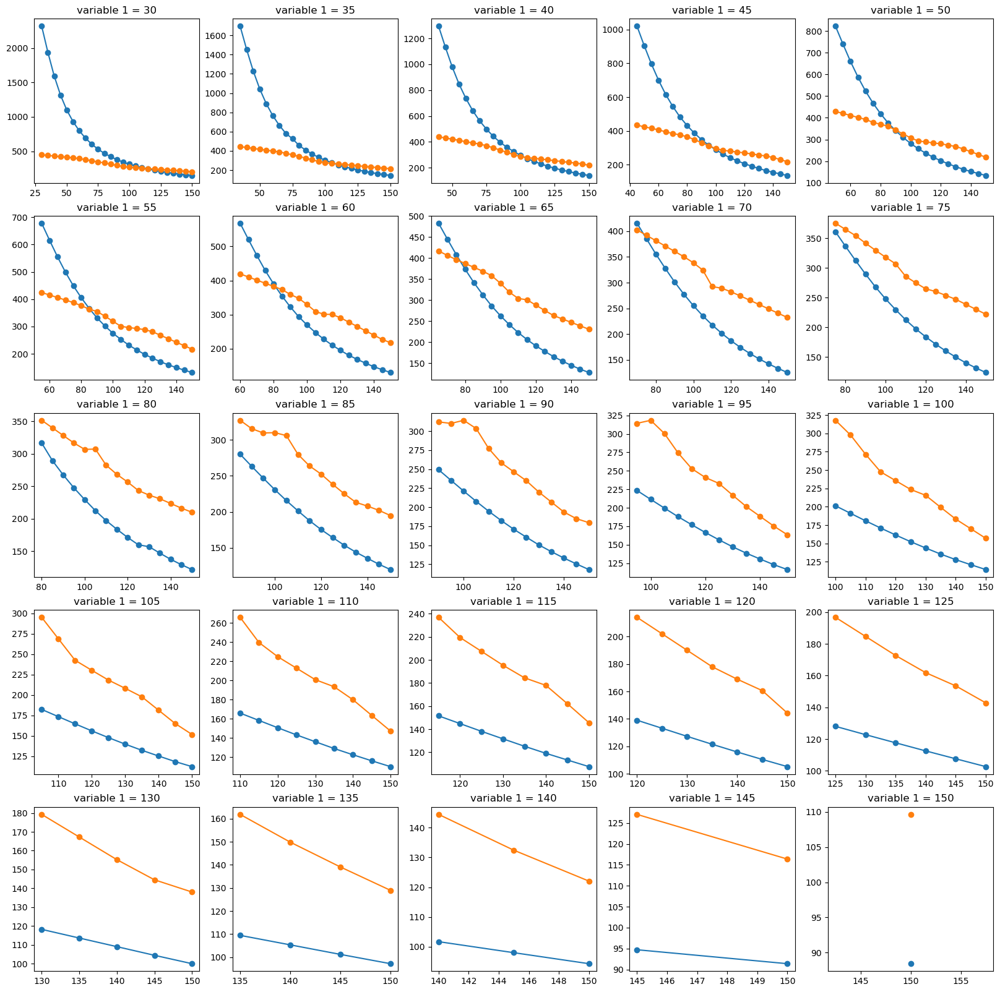

In [44]:
plot2d_var1const('NN')

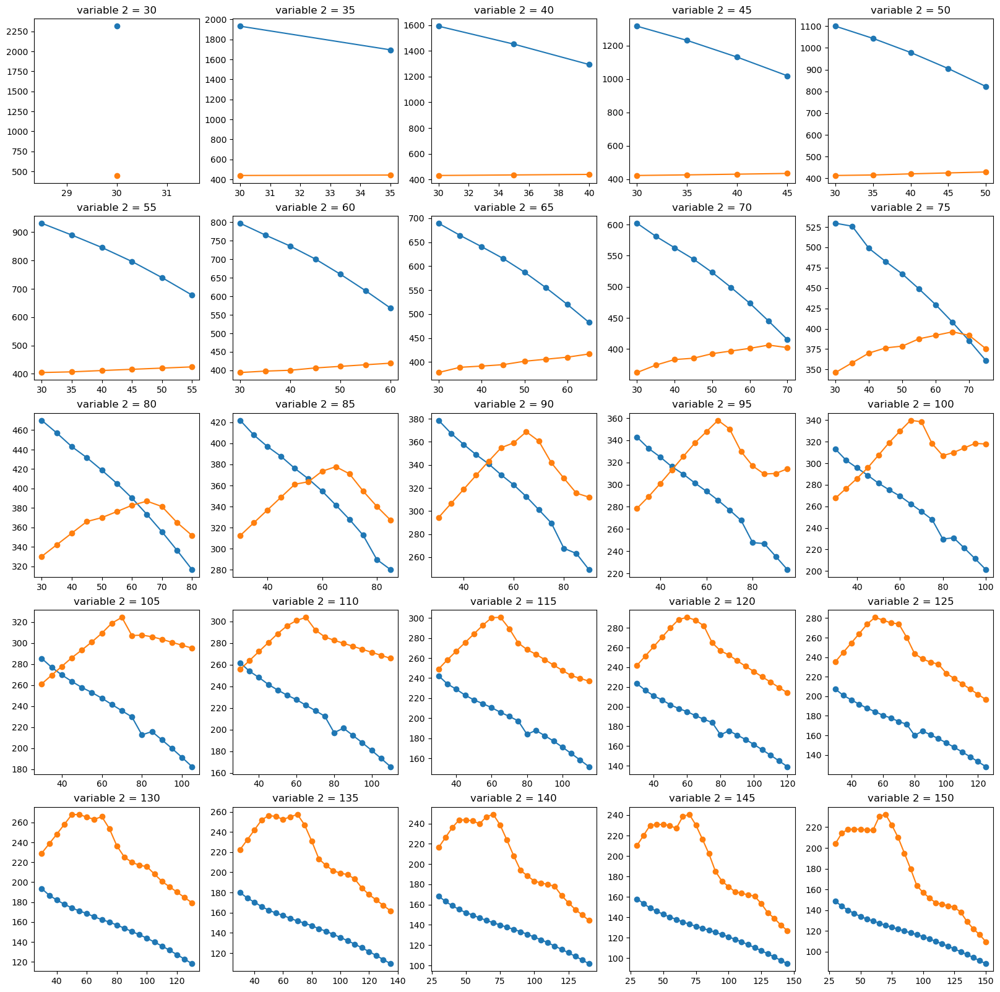

In [45]:
plot2d_var2const('NN')

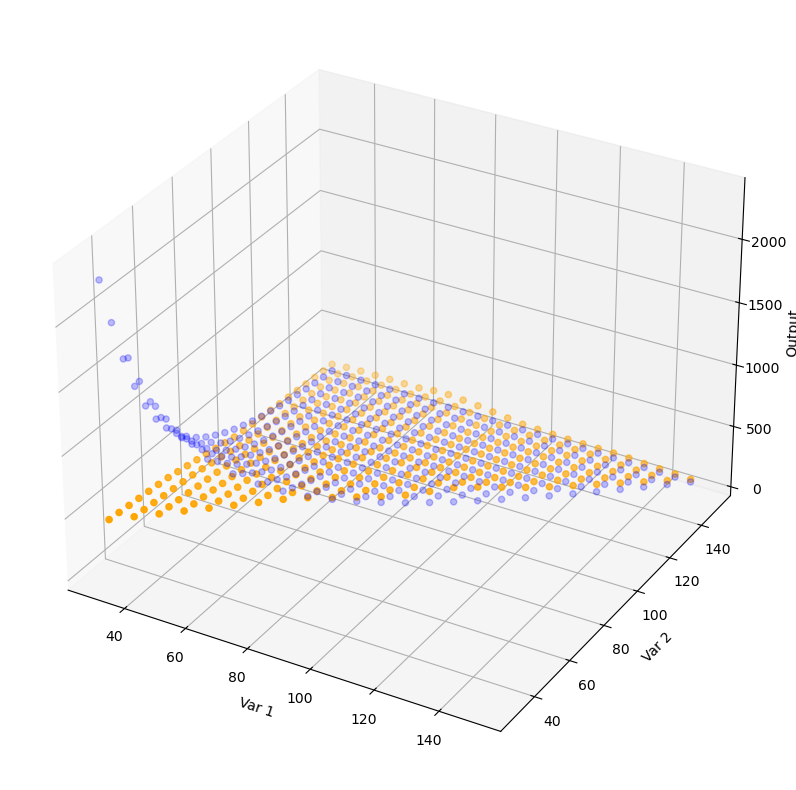

In [46]:
plot3d('NN')

In [47]:
df['Output'].values

array([2315.7  , 1932.6  , 1592.2  , 1316.6  , 1099.5  ,  931.63 ,
        797.07 ,  689.49 ,  602.12 ,  529.58 ,  470.11 ,  421.96 ,
        378.61 ,  342.78 ,  313.01 ,  285.26 ,  261.88 ,  242.24 ,
        223.3  ,  207.23 ,  193.55 ,  180.01 ,  168.44 ,  158.01 ,
        148.54 , 1696.1  , 1452.8  , 1231.3  , 1043.3  ,  889.97 ,
        765.4  ,  664.18 ,  581.15 ,  525.95 ,  457.11 ,  407.98 ,
        367.27 ,  332.6  ,  302.65 ,  276.7  ,  253.97 ,  234.07 ,
        216.5  ,  200.86 ,  186.89 ,  174.43 ,  163.17 ,  153.58 ,
        143.8  , 1294.3  , 1131.   ,  978.57 ,  846.07 ,  735.4  ,
        640.69 ,  562.72 ,  498.81 ,  443.08 ,  396.97 ,  357.7  ,
        324.93 ,  295.72 ,  269.6  ,  248.26 ,  228.84 ,  210.91 ,
        196.34 ,  182.08 ,  170.44 ,  158.89 ,  148.99 ,  139.98 ,
       1019.4  ,  904.73 ,  796.7  ,  700.53 ,  616.17 ,  544.54 ,
        482.61 ,  431.74 ,  387.57 ,  348.78 ,  316.23 ,  288.78 ,
        263.4  ,  241.83 ,  222.88 ,  206.75 ,  191.85 ,  177.

In [48]:
df['NN'].values

array([448.8154 , 439.63815, 430.605  , 421.9671 , 413.19827, 404.42944,
       394.2265 , 378.2297 , 362.23288, 346.23605, 330.20245, 312.2876 ,
       294.3727 , 278.5828 , 267.6021 , 261.03656, 255.6689 , 249.03752,
       241.91325, 235.47888, 229.0445 , 222.61012, 216.34004, 210.28008,
       204.22014, 443.92035, 434.74313, 425.56592, 415.47342, 406.8022 ,
       398.03336, 389.1331 , 374.1653 , 358.16846, 342.17166, 324.49783,
       306.58295, 289.17917, 276.68155, 269.31842, 263.95074, 258.24332,
       251.45029, 245.01593, 238.58153, 232.2155 , 226.15558, 220.09563,
       214.0357 , 439.02533, 429.8481 , 420.6709 , 411.49368, 400.34183,
       391.6373 , 383.09668, 370.1009 , 354.10406, 336.70804, 318.79318,
       300.87833, 285.76102, 277.60028, 272.23264, 266.86496, 260.9873 ,
       254.55293, 248.11855, 242.03105, 235.9711 , 229.91115, 217.97466,
       434.13034, 424.9531 , 415.77585, 406.59866, 394.61105, 385.21027,
       376.4724 , 366.03647, 348.91827, 331.00342, 

# All Results

In [49]:
df

,variable 1,variable 2,Output,custom,Linreg,DTReg,RFReg,GBR,ABR,XGB,LGBM,NN
0,30,30,2315.700,2275.557132,929.492625,2315.700000,2200.770000,2265.459092,2315.700000,1908.496094,1369.554931,448.815399
1,30,35,1932.600,1878.507927,892.620457,1814.350000,2009.220000,1898.043524,1932.600000,1852.588379,1369.554931,439.638153
2,30,40,1592.200,1561.149755,855.748288,1446.433333,1636.990000,1568.093904,1469.985714,1513.691650,1369.554931,430.605011
3,30,45,1316.600,1306.986398,818.876120,1133.378333,1276.330000,1296.628279,1180.877778,1244.475830,1369.554931,421.967102
4,30,50,1099.500,1102.936387,782.003951,1133.378333,1071.473000,1069.554477,935.830000,1071.644531,1369.554931,413.198273
...,...,...,...,...,...,...,...,...,...,...,...,...
320,140,145,97.999,96.875945,-27.577436,122.609127,98.464250,109.795820,141.344716,106.754135,101.333581,132.435059
321,140,150,94.303,88.224427,-64.449604,122.609127,95.387582,107.505190,141.344716,106.754135,97.150664,122.051964
322,145,145,94.712,94.593612,-32.532444,122.609127,95.804054,109.795820,141.344716,106.754135,101.333581,127.051628
323,145,150,91.383,86.181977,-69.404612,122.609127,91.997586,107.505190,141.344716,106.754135,97.150664,116.376060


In [50]:
# df.to_csv('All models results.csv')